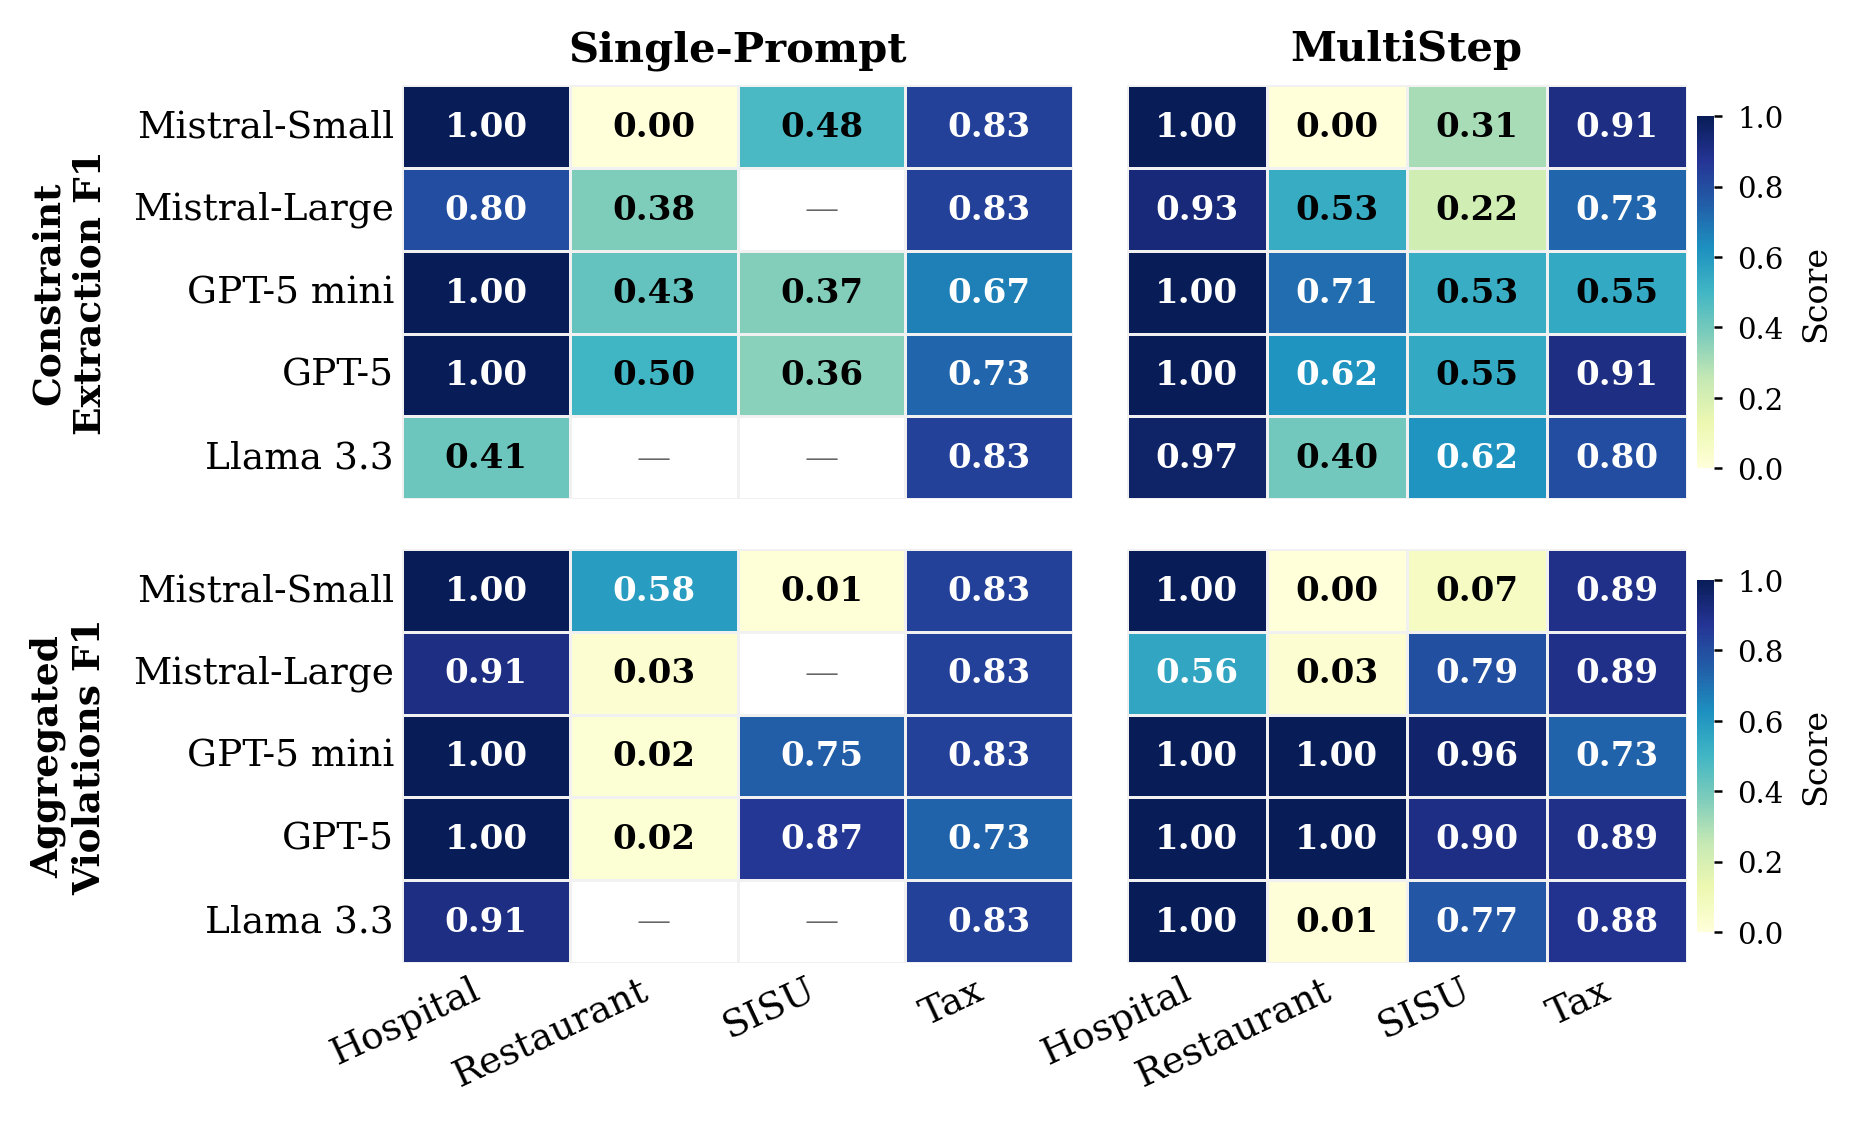

Saved heatmap to `best_mapping.pdf` and `best_mapping.png`

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display, Markdown

# ── Publication style ──────────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.titlesize":    10,
    "axes.labelsize":    9,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "figure.dpi":        300,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "text.usetex":       False,   # set True if LaTeX is available
    "axes.linewidth":    0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})


# Notebook-ready script
# ---------------------
# Reads a CSV with model-selection results and generates two LaTeX booktabs tables:
#   1) LLM mapper
#   2) MultiStep mapper
#
# Layout: datasets as row groups, metrics as columns.
# Rows = models, Groups = datasets, Columns = 3 metrics.

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import matplotlib.colors as mcolors

# ============================================================
# 1) CONFIGURATION YOU MAY WANT TO EDIT
# ============================================================

CSV_PATH = "results_summary_all.csv"   # change if needed
ONLY_SUCCESS = True
DECIMALS = 2

# Metrics to show in the table.
# "kind" controls how the column is rendered:
#   - "single": one numeric column
#   - "mean_std": render as "mean ± std", ranked by the mean
METRICS = [
    {
        "key": "constraint_exact_f1",
        "label": "Constraint\nExact F1",
        "kind": "single",
    },
    {
        "key": "pairwise_viol_f1",
        "label": "Pairwise Viol.\nF1",
        "kind": "mean_std",
        "mean_col": "pairwise_viol_f1_mean",
        "std_col": "pairwise_viol_f1_std",
    },
    {
        "key": "agg_viol_f1",
        "label": "Aggregate\nViol. F1",
        "kind": "single",
    },
]

# Order of implementations in output
IMPLEMENTATION_ORDER = ["llm", "multi_step_refinement"]

# Order of datasets in output; any dataset not listed here will be appended alphabetically
DATASET_ORDER = [
    "hospital",
    "restaurant",
    "sisu",
    "tax",
]

# Order of models in output; any model not listed here will be appended alphabetically
MODEL_ORDER = [
    "mistral-small-2506",
    "mistral-large-2512",
    "gpt-5-mini",
    "gpt-5",
    "llama-3.3-70b-versatile",
]

# Pretty names used in the table rows
MODEL_DISPLAY = {
    "mistral-small-2506":      "Mistral-Small",
    "mistral-large-2512":      "Mistral-Large",
    "llama-3.3-70b-versatile": "Llama 3.3",
    "gpt-5-mini":              "GPT-5 mini",
    "gpt-5":                   "GPT-5",
}

# Pretty dataset names used in row-group headers
DATASET_DISPLAY = {
    "tax":        "Tax",
    "hospital":   "Hospital",
    "restaurant": "Restaurant",
    "sisu":       "SISU",
}

# Pretty implementation names used in captions / labels / headings
IMPLEMENTATION_DISPLAY = {
    "llm": "Single-Prompt",
    "multi_step_refinement": "Multi-Step",
}

# Optional: if you want to override row grouping by implementation based on variant_name
IMPLEMENTATION_VARIANT_HINTS = {
    "LLM": "llm",
    "Multi-Step": "multi_step_refinement",
}

# LaTeX labels
LABELS = {
    "llm": "tab:model-selection-llm",
    "multi_step_refinement": "tab:model-selection-multistep",
}


main_metrics = ["constraint_exact_f1", "agg_viol_f1"]
metric_labels = {
    "constraint_exact_f1": "Constraint\nExtraction F1",
    "agg_viol_f1":         "Aggregated\nViolations F1",
}

# Better sequential colormap for publication heatmaps
cmap = "YlGnBu"

# Ordered model / dataset display lists (depend on cell 1 variables)
ordered_models   = [model_display[m]   for m in models   if m in model_display]
ordered_datasets = [dataset_display[d] for d in datasets if d in dataset_display]

n_impl    = len(IMPLEMENTATION_ORDER)
n_metrics = len(main_metrics)

# ── Grid: rows = metrics, cols = implementations ───────────────────────────────
fig, axes = plt.subplots(
    n_metrics, n_impl,
    figsize=(3.0 * n_impl, 1.9 * n_metrics),
    gridspec_kw={"hspace": 0.12, "wspace": 0.08},
)

# Guarantee 2-D indexing
if n_metrics == 1 and n_impl == 1:
    axes = [[axes]]
elif n_metrics == 1:
    axes = [axes]
elif n_impl == 1:
    axes = [[ax] for ax in axes]

def _fmt(v):
    return f"{v:.2f}" if not pd.isna(v) else "—"

for row_idx, metric in enumerate(main_metrics):
    for col_idx, impl in enumerate(IMPLEMENTATION_ORDER):
        ax = axes[row_idx][col_idx]

        df_impl = df[df["implementation_canonical"] == impl].copy()
        df_impl["model_d"]   = df_impl["model"].map(model_display)
        df_impl["dataset_d"] = df_impl["dataset"].map(dataset_display)

        heat_data = (
            df_impl.groupby(["model_d", "dataset_d"])[metric]
            .mean()
            .unstack("dataset_d")
            .reindex(index=ordered_models, columns=ordered_datasets)
        )

        show_xticklabels = (row_idx == n_metrics - 1)
        show_yticklabels = (col_idx == 0)
        show_cbar        = (col_idx == n_impl - 1)

        hm = sns.heatmap(
            heat_data,
            ax=ax,
            annot=False,  # manual annotation below for better contrast control
            cmap=cmap,
            vmin=0.0,
            vmax=1.0,
            linewidths=0.25,
            linecolor="#f1f1f1",
            cbar=show_cbar,
            cbar_kws={"shrink": 0.85, "label": "Score", "pad": 0.015},
            xticklabels=show_xticklabels,
            yticklabels=show_yticklabels,
        )

        # Manual annotations with dynamic text color
        col_max = heat_data.max(axis=0, skipna=True)

        for i in range(heat_data.shape[0]):
            for j in range(heat_data.shape[1]):
                val = heat_data.iloc[i, j]
                label = _fmt(val)

                if pd.isna(val):
                    txt_color = "#666666"
                    fontweight = "normal"
                else:
                    txt_color = "white" if val >= 0.55 else "black"
                    fontweight = "bold" if val == col_max.iloc[j] else "semibold"

                ax.text(
                    j + 0.5, i + 0.5, label,
                    ha="center", va="center",
                    fontsize=8.2,
                    color=txt_color,
                    fontweight=fontweight,
                )

        # Implementation name as column title (top row only)
        if row_idx == 0:
            ax.set_title(
                IMPLEMENTATION_DISPLAY.get(impl, impl),
                fontweight="bold",
                pad=6
            )

        # Metric label on leftmost column only
        if show_yticklabels:
            ax.set_ylabel(metric_labels[metric], labelpad=6, fontweight="bold")
        else:
            ax.set_ylabel("")

        ax.set_xlabel("")

        # Rotate x-tick labels on bottom row only
        if show_xticklabels:
            ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")

        # Keep y-tick labels horizontal on leftmost column
        if show_yticklabels:
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

        ax.tick_params(length=0, pad=2)

        # Remove heavy subplot borders
        for spine in ax.spines.values():
            spine.set_visible(False)

        if show_cbar:
            cbar = hm.collections[0].colorbar
            cbar.ax.tick_params(labelsize=7, length=2)
            cbar.set_label("Score", size=8)

plt.savefig("best_mapping.pdf", format="pdf")
plt.savefig("best_mapping.png", format="png")
plt.show()
display(Markdown("Saved heatmap to `best_mapping.pdf` and `best_mapping.png`"))